# Fase 1 y 2 (CRISP-DM): Análisis Exploratorio de Datos (EDA) y Preparación de Datos
**Proyecto:** Clasificación de Calidad (`good`, `regular`, `bad`) y Tamaño (`pequeño`, `mediano`, `grande`) de Frutas (`ProyectoFinalAPO3`)

Este notebook está conectado directamente con `src/data/build_dataset.py` y `src/data/preprocess.py` para:
1. **Comprensión de los Datos (EDA):** Analizar las 11,544 imágenes consolidadas en `data_processed/labels.csv`, su distribución por fuente (`kaggle` vs `recolectado`), tipo de fruta, calidad y tamaño relativo.
2. **Preparación de los Datos:** Validar la segmentación con máscara HSV, la extracción de características geométricas + histograma HSV (`extract_ml_features`), el preprocesamiento de imágenes para CNN (`preprocess_image_for_cnn`) y la partición estratificada `train / val / test` (`split_dataset`).

In [2]:

# ============================================================
# 1. CONFIGURACIÓN E IMPORTACIÓN DE LIBRERÍAS
# ============================================================

import sys
from pathlib import Path

# Identificar la carpeta principal del proyecto
current_dir = Path.cwd().resolve()

PROJECT_ROOT = (
    current_dir.parent
    if current_dir.name == "notebooks"
    else current_dir
)

# Permitir importar los módulos de src
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Librerías
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Funciones originales del proyecto
from src.data.build_dataset import get_fruit_mask_and_size

from src.data.preprocess import (
    load_labels_df,
    split_dataset,
    extract_ml_features,
    preprocess_image_for_cnn,
    prepare_ml_split,
)

# Funciones nuevas para la integración con rembg
from src.data.preprocess import (
    load_rembg_recolectado_df,
    extract_ml_features_rembg,
    prepare_ml_split_rembg,
    prepare_cnn_split_rembg,
)

# Configuración visual
sns.set_theme(style="whitegrid")

# Cargar el inventario de fotografías
df = load_labels_df()

print("Raíz del proyecto:", PROJECT_ROOT)
print("Total de registros:", len(df))
print("Fotografías recolectadas:", (df["source"] == "recolectado").sum())
print("Registros de Kaggle:", (df["source"] == "kaggle").sum())

display(df.head())


Raíz del proyecto: /home/anderson/Descargas/Apo3/ProyectoFInalAPO3/ProyectoFinalAPO3
Total de registros: 11544
Fotografías recolectadas: 219
Registros de Kaggle: 11325


,filepath,source,fruit,quality,size_label,relative_diameter
0,data_raw/kaggle/archive/Bad Quality_Fruits/App...,kaggle,apple,bad,mediano,0.4309
1,data_raw/kaggle/archive/Bad Quality_Fruits/App...,kaggle,apple,bad,mediano,0.4224
2,data_raw/kaggle/archive/Bad Quality_Fruits/App...,kaggle,apple,bad,mediano,0.4190
3,data_raw/kaggle/archive/Bad Quality_Fruits/App...,kaggle,apple,bad,mediano,0.4569
4,data_raw/kaggle/archive/Bad Quality_Fruits/App...,kaggle,apple,bad,mediano,0.3826


## 1. Comprensión de los Datos (EDA)
### 1.1 Distribución por Fruta, Calidad, Fuente y Tamaño

=== Distribución por Fruta y Calidad ===


quality,good,regular,bad,All
fruit,,,,
apple,1179,5,1171,2355
banana,1122,14,1099,2235
guava,1152,8,1136,2296
lime,1094,0,1085,2179
orange,1254,36,1189,2479
All,5801,63,5680,11544



=== Distribución por Fruta y Tamaño ===


size_label,pequeño,mediano,grande,All
fruit,,,,
apple,155,959,1241,2355
banana,244,1100,891,2235
guava,341,1071,884,2296
lime,544,1404,231,2179
orange,253,979,1247,2479
All,1537,5513,4494,11544


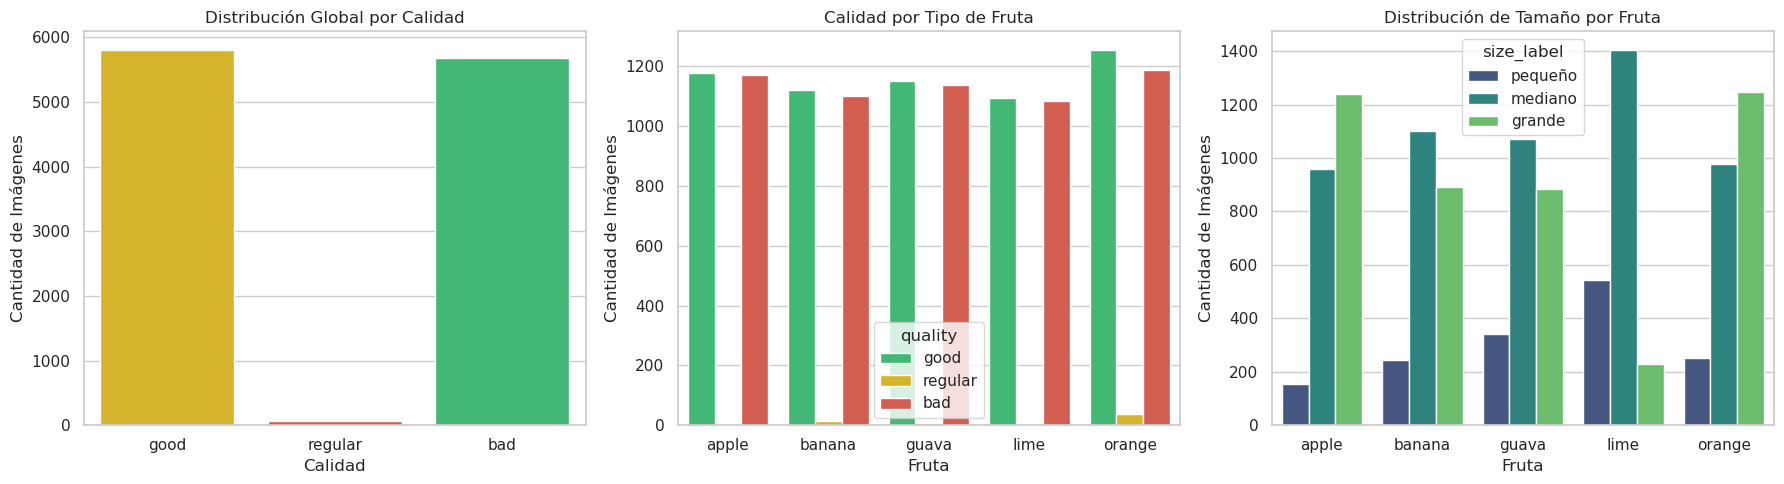

In [3]:
order_quality = ['good', 'regular', 'bad']
order_size = ['pequeño', 'mediano', 'grande']
palette_quality = ['#2ecc71', '#f1c40f', '#e74c3c']

print('=== Distribución por Fruta y Calidad ===')
display(pd.crosstab(df['fruit'], df['quality'], margins=True).reindex(columns=order_quality + ['All'], fill_value=0))

print('\n=== Distribución por Fruta y Tamaño ===')
display(pd.crosstab(df['fruit'], df['size_label'], margins=True).reindex(columns=order_size + ['All'], fill_value=0))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Calidad Global
sns.countplot(
    data=df, x='quality', hue='quality',
    order=order_quality, palette=palette_quality, legend=False, ax=axes[0]
)
axes[0].set_title('Distribución Global por Calidad')
axes[0].set_xlabel('Calidad')
axes[0].set_ylabel('Cantidad de Imágenes')

# Gráfico 2: Calidad por Fruta
sns.countplot(
    data=df, x='fruit', hue='quality',
    hue_order=order_quality, palette=palette_quality, ax=axes[1]
)
axes[1].set_title('Calidad por Tipo de Fruta')
axes[1].set_xlabel('Fruta')
axes[1].set_ylabel('Cantidad de Imágenes')

# Gráfico 3: Tamaño por Fruta
sns.countplot(
    data=df, x='fruit', hue='size_label',
    hue_order=order_size, palette='viridis', ax=axes[2]
)
axes[2].set_title('Distribución de Tamaño por Fruta')
axes[2].set_xlabel('Fruta')
axes[2].set_ylabel('Cantidad de Imágenes')

plt.tight_layout()
plt.show()

### 1.2 Distribución del diámetro relativo (`relative_diameter`) por fruta

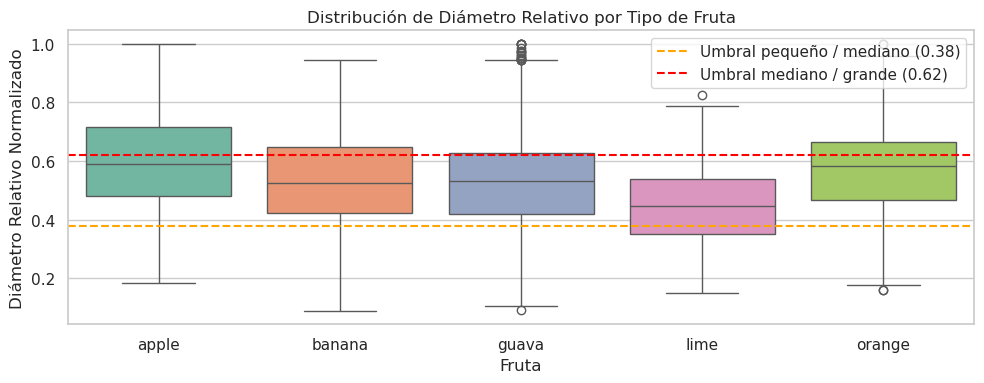

In [4]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x='fruit', y='relative_diameter', hue='fruit', palette='Set2', legend=False)
plt.axhline(0.38, color='orange', linestyle='--', label='Umbral pequeño / mediano (0.38)')
plt.axhline(0.62, color='red', linestyle='--', label='Umbral mediano / grande (0.62)')
plt.title('Distribución de Diámetro Relativo por Tipo de Fruta')
plt.xlabel('Fruta')
plt.ylabel('Diámetro Relativo Normalizado')
plt.legend()
plt.tight_layout()
plt.show()

## 2. Preparación de los Datos (`src/data/preprocess.py`)
### 2.1 Validación visual de segmentación (máscara), tensor HSV para CNN y vector de características ML

In [5]:

# ============================================================
# SELECCIÓN DE LAS FOTOGRAFÍAS RECOLECTADAS
# ============================================================

# Seleccionar únicamente las imágenes recolectadas.
df_recolectado = df[
    df["source"] == "recolectado"
].copy()

# Verificar que las fotografías existan.
df_recolectado["existe"] = df_recolectado[
    "filepath"
].apply(
    lambda ruta: (PROJECT_ROOT / ruta).is_file()
)

print("Fotografías recolectadas:", len(df_recolectado))

print(
    "Fotografías disponibles:",
    df_recolectado["existe"].sum()
)

print("\nDistribución por fruta y calidad:")

display(
    pd.crosstab(
        df_recolectado["fruit"],
        df_recolectado["quality"],
        margins=True
    )
)


Fotografías recolectadas: 219
Fotografías disponibles: 219

Distribución por fruta y calidad:


quality,bad,good,regular,All
fruit,,,,
apple,30,30,5,65
banana,12,9,14,35
guava,7,0,8,15
orange,30,38,36,104
All,79,77,63,219


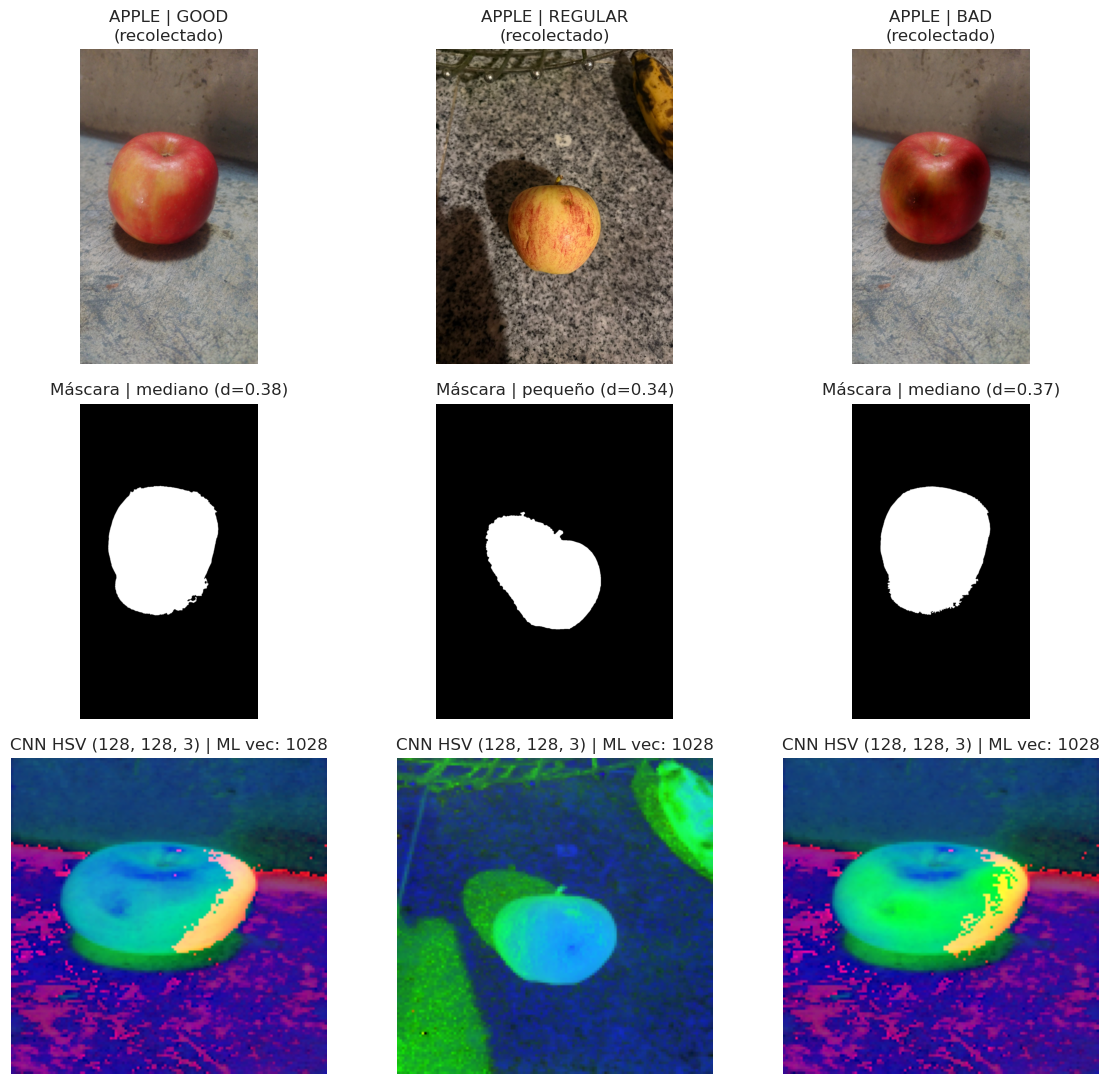

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(12, 11))

for col_idx, q in enumerate(order_quality):
    sample = df_recolectado[
    (df_recolectado["quality"] == q)
    & (df_recolectado["existe"])
    ].iloc[0]    
    img_path = PROJECT_ROOT / sample['filepath']
    img_bgr = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # 1. Máscara y tamaño desde build_dataset.py
    mask, rel_diam, size_lbl = get_fruit_mask_and_size(img_bgr)
    
    # 2. Tensor HSV normalizado (128x128x3) desde preprocess.py
    cnn_tensor = preprocess_image_for_cnn(img_bgr, target_size=(128, 128))
    
    # 3. Vector de características 1D para ML tradicional (1024 HSV bins + 4 geométricas = 1028)
    ml_vec = extract_ml_features(img_bgr)
    
    # Fila 0: Imagen Original RGB
    axes[0, col_idx].imshow(img_rgb)
    axes[0, col_idx].set_title(f"{sample['fruit'].upper()} | {q.upper()}\n({sample['source']})")
    axes[0, col_idx].axis('off')
    
    # Fila 1: Máscara de Segmentación
    axes[1, col_idx].imshow(mask, cmap='gray')
    axes[1, col_idx].set_title(f"Máscara | {size_lbl} (d={rel_diam:.2f})")
    axes[1, col_idx].axis('off')
    
    # Fila 2: Imagen Preprocesada CNN (HSV normalizado 128x128)
    axes[2, col_idx].imshow(cnn_tensor)
    axes[2, col_idx].set_title(f"CNN HSV {cnn_tensor.shape} | ML vec: {ml_vec.shape[0]}")
    axes[2, col_idx].axis('off')

plt.tight_layout()
plt.show()


### 2.2 Segmentación de frutas mediante rembg

Se aplica el modelo preentrenado rembg a las fotografías recolectadas para obtener las máscaras binarias y aislar las frutas sobre fondo negro. Posteriormente, las imágenes se recortan y redimensionan a 224 × 224 píxeles, conservando sus proporciones.

Las máscaras y las imágenes procesadas se almacenan para su utilización en la extracción de características y la preparación de los modelos.


In [6]:
# ============================================================
# 2.2 SEGMENTACIÓN DE LAS FOTOGRAFÍAS RECOLECTADAS
# ============================================================

from src.data.segmentation_rembg import procesar_dataset

procesar_dataset(limite=None)

SEGMENTACIÓN REMBG - APO 3
Fotografías seleccionadas: 219
[1/219] apple / bad: generada
[2/219] apple / bad: generada
[3/219] apple / bad: generada
[4/219] apple / bad: generada
[5/219] apple / bad: generada
[6/219] apple / bad: generada
[7/219] apple / bad: generada
[8/219] apple / bad: generada
[9/219] apple / bad: generada
[10/219] apple / bad: generada
[11/219] apple / bad: generada
[12/219] apple / bad: generada
[13/219] apple / bad: generada
[14/219] apple / bad: generada
[15/219] apple / bad: generada
[16/219] apple / bad: generada
[17/219] apple / bad: generada
[18/219] apple / bad: generada
[19/219] apple / bad: generada
[20/219] apple / bad: generada
[21/219] apple / bad: generada
[22/219] apple / bad: generada
[23/219] apple / bad: generada
[24/219] apple / bad: generada
[25/219] apple / bad: generada
[26/219] apple / bad: generada
[27/219] apple / bad: generada
[28/219] apple / bad: generada
[29/219] apple / bad: generada
[30/219] apple / bad: generada
[31/219] orange / bad

Fotografías evaluadas: 219

Estados del procesamiento:


status
generada    219
Name: count, dtype: int64

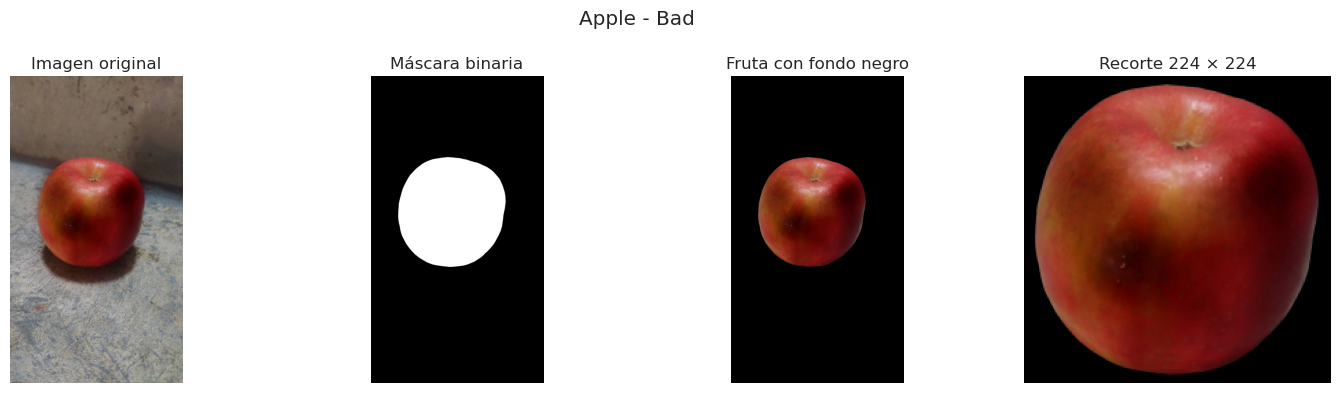

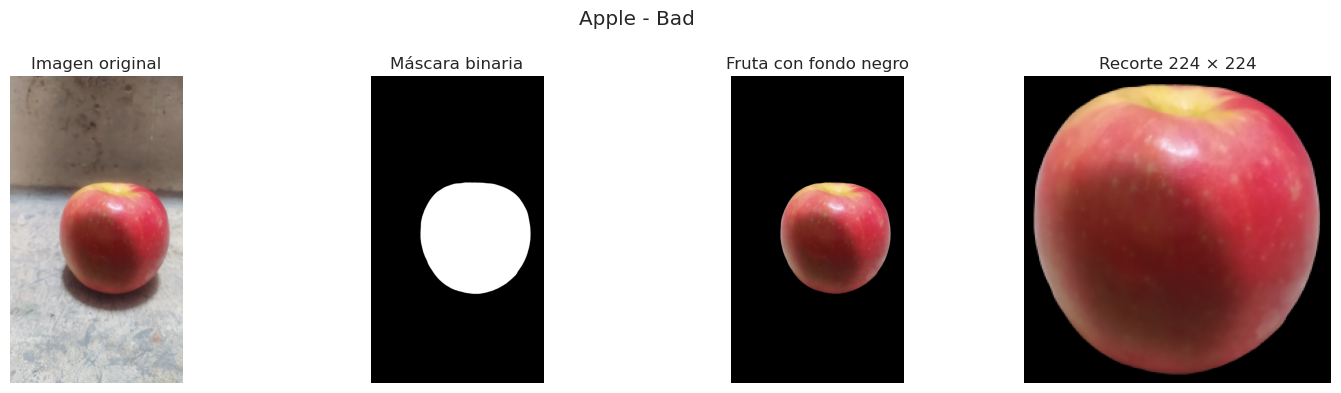

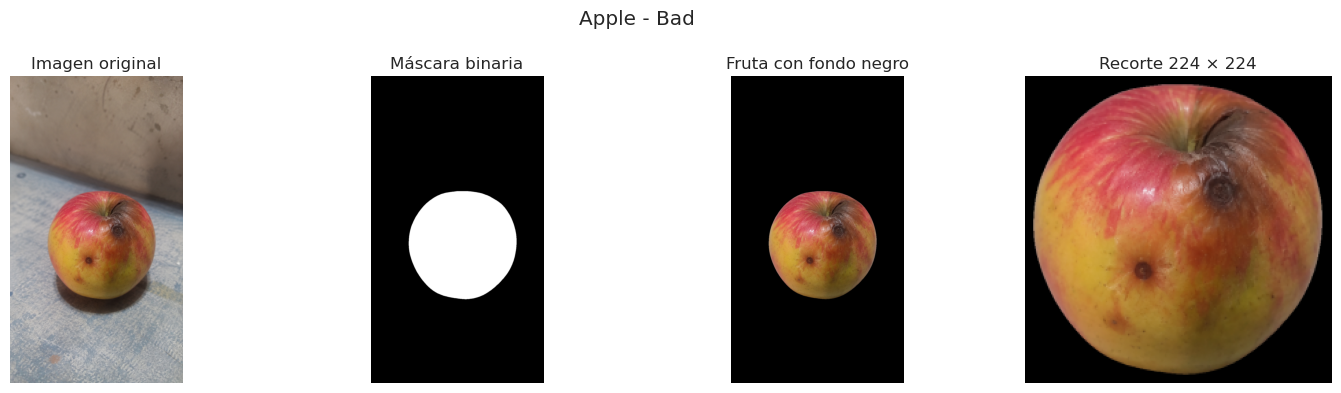

In [7]:

# ============================================================
# 2.2.1 REVISIÓN VISUAL DE LA SEGMENTACIÓN REMBG
# ============================================================

ruta_reporte = (
    PROJECT_ROOT
    / "data_processed"
    / "rembg_recolectado_manifest.csv"
)

resultados = pd.read_csv(ruta_reporte)

print("Fotografías evaluadas:", len(resultados))
print("\nEstados del procesamiento:")
display(resultados["status"].value_counts())

# Seleccionar fotografías con imágenes generadas.
validas = resultados[
    resultados["status"].isin(["generada", "revisar"])
].head(3)

for _, fila in validas.iterrows():

    def cargar(ruta, color=True):
        imagen = cv2.imread(
            str(PROJECT_ROOT / ruta),
            cv2.IMREAD_COLOR if color else cv2.IMREAD_GRAYSCALE
        )

        if imagen is None:
            raise FileNotFoundError(ruta)

        if color:
            return cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

        return imagen

    original = cargar(fila["filepath"])
    mascara = cargar(fila["mask_filepath"], color=False)
    aislada = cargar(fila["isolated_filepath"])
    recorte = cargar(fila["cnn_filepath"])

    fig, axes = plt.subplots(1, 4, figsize=(15, 4))

    imagenes = [original, mascara, aislada, recorte]
    titulos = [
        "Imagen original",
        "Máscara binaria",
        "Fruta con fondo negro",
        "Recorte 224 × 224"
    ]

    for ax, imagen, titulo in zip(axes, imagenes, titulos):
        if titulo == "Máscara binaria":
            ax.imshow(imagen, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(imagen)

        ax.set_title(titulo)
        ax.axis("off")

    plt.suptitle(
        f"{fila['fruit'].capitalize()} - "
        f"{fila['quality'].capitalize()}"
    )

    plt.tight_layout()
    plt.show()


In [9]:
# ============================================================
# 2.2.3 VERIFICACIÓN DEL PROCESAMIENTO COMPLETO
# ============================================================

df_recolectado = df[df["source"] == "recolectado"].copy()

ruta_manifest = (
    PROJECT_ROOT
    / "data_processed"
    / "rembg_recolectado_manifest.csv"
)

manifest = pd.read_csv(ruta_manifest)

estados_validos = ["generada", "revisar"]

print("Fotografías originales:", len(df_recolectado))
print("Registros de segmentación:", len(manifest))

print("\nEstados de segmentación:")
display(manifest["status"].value_counts().to_frame("Cantidad"))

# Comprobar que cada fotografía tenga su registro.
rutas_originales = set(df_recolectado["filepath"])
rutas_procesadas = set(manifest["filepath"])

faltantes = rutas_originales - rutas_procesadas

print("\nFotografías sin registro:", len(faltantes))

# Verificar los archivos de salida.
columnas = [
    "mask_filepath",
    "isolated_filepath",
    "cnn_filepath"
]

validas = manifest[
    manifest["status"].isin(estados_validos)
].copy()

for columna in columnas:
    validas = validas[
        validas[columna].notna()
        & validas[columna].apply(
            lambda ruta: (
                PROJECT_ROOT / str(ruta)
            ).is_file()
        )
    ].copy()

print("Fotografías con archivos disponibles:", len(validas))
print("Fotografías pendientes:", len(df_recolectado) - len(validas))

Fotografías originales: 219
Registros de segmentación: 219

Estados de segmentación:


,Cantidad
status,
generada,219



Fotografías sin registro: 0
Fotografías con archivos disponibles: 219
Fotografías pendientes: 0


### 2.2 Partición Estratificada (`train / val / test`) y Extracción de Matrices ML
Aplicamos `split_dataset` (70% train, 15% val, 15% test estratificado por `fruit + quality`) y luego generamos las matrices `X_train`, `X_val` y `X_test` usando `prepare_ml_split` con aumento de datos (`augment_minorities=True`, `target_per_quality=300`) **únicamente sobre `train`** para balancear la clase `regular`.

In [ ]:
train_df, val_df, test_df = split_dataset(df, test_size=0.15, val_size=0.15, random_state=42)

print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')
print('\nDistribución de calidad en Train (antes de augmentación):')
print(train_df['quality'].value_counts())

# Extraer características ML (HSV enmascarado + 4 descriptores geométricos = 1028 features)
X_train, y_qual_train, y_size_train = prepare_ml_split(train_df, augment_minorities=True, target_per_quality=300)
X_val, y_qual_val, y_size_val = prepare_ml_split(val_df, augment_minorities=False)
X_test, y_qual_test, y_size_test = prepare_ml_split(test_df, augment_minorities=False)

print('\nMatrices ML generadas:')
print(f'X_train: {X_train.shape} | Distribución calidad train balanceada: {np.bincount(y_qual_train)}')
print(f'X_val:   {X_val.shape} | Distribución calidad val:              {np.bincount(y_qual_val)}')
print(f'X_test:  {X_test.shape} | Distribución calidad test:             {np.bincount(y_qual_test)}')

### 2.3 Guardado de particiones y matrices procesadas en `data_processed/`

In [ ]:
processed_dir = PROJECT_ROOT / 'data_processed'
processed_dir.mkdir(parents=True, exist_ok=True)

# Guardar CSVs de los splits para que la CNN use exactamente las mismas particiones
train_df.to_csv(processed_dir / 'train_split.csv', index=False)
val_df.to_csv(processed_dir / 'val_split.csv', index=False)
test_df.to_csv(processed_dir / 'test_split.csv', index=False)

# Guardar matrices listas para modelos de ML tradicional (Random Forest, SVM, KNN, etc.)
np.savez_compressed(
    processed_dir / 'ml_features_splits.npz',
    X_train=X_train, y_qual_train=y_qual_train, y_size_train=y_size_train,
    X_val=X_val, y_qual_val=y_qual_val, y_size_val=y_size_val,
    X_test=X_test, y_qual_test=y_qual_test, y_size_test=y_size_test,
)

print('Archivos guardados en data_processed/:')
for f in sorted(processed_dir.iterdir()):
    print(' -', f.name)